# Plastic pyrolysis oil yield - real data (Belden 2023)

Same techniques as the synthetic 3-fraction notebook, but on the **real**
325-row dataset compiled by Belden et al. (2023) from 39 papers. Two differences
driven by the data:

- Feedstock is given as **mass-fraction columns** (HDPE, LDPE, PP, PS, PVC, PET),
  so mixtures are first-class.
- The only reported target is **oil (liquid) yield** - no gas/solid split - so
  this is a single-target regression.

Everything else carries over: RandomForest / XGBoost / LightGBM compared with
cross-validation, SHAP, conformal intervals, an in-domain flag, and a condition
recommender (here: conditions that maximize oil yield for a given feedstock).
The paper's benchmark was XGBoost at test MAE 9.1 %.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import shap
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA_DIR = Path("data") if Path("data").exists() else Path("../data")
MODEL_DIR = Path("models") if Path("models").exists() else Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (7, 4)

## 2. Load the real dataset

In [2]:
df = pd.read_csv(DATA_DIR / "reference" / "belden2023_oilyield.csv")
print("shape:", df.shape, "| source papers:", df.source_ref.nunique())
print(df["oil_yield_wpct"].describe().round(1).to_string())
df.head()

shape: (325, 15) | source papers: 39
count    325.0
mean      62.2
std       24.0
min        2.0
25%       42.9
50%       70.0
75%       80.6
max       99.0


,HDPE_wt,LDPE_wt,PP_wt,PS_wt,PVC_wt,PET_wt,plastic_sum_wt,temperature_C,heating_rate_C_min,particle_size_mm,feed_mass_g,catalyst,reactor_type,oil_yield_wpct,source_ref
0,0.0,100.0,0.0,0.0,0.0,0.0,100.0,500.0,10.0,2.5,NaN,No,Fixed Bed,95.0,1
1,0.0,100.0,0.0,0.0,0.0,0.0,100.0,400.0,10.0,2.5,NaN,Yes,Fixed Bed,84.0,1
2,0.0,100.0,0.0,0.0,0.0,0.0,100.0,450.0,10.0,2.5,NaN,Yes,Fixed Bed,81.0,1
3,0.0,100.0,0.0,0.0,0.0,0.0,100.0,500.0,10.0,2.5,NaN,Yes,Fixed Bed,80.0,1
4,0.0,100.0,0.0,0.0,0.0,0.0,100.0,550.0,10.0,2.5,NaN,Yes,Fixed Bed,76.0,1


## 3. Explore

Oil yield spans almost the whole 0-100 range. Polyolefins (PE, PP, PS) tend to
give high oil; PET and PVC drag it down. Temperature has the classic hump.

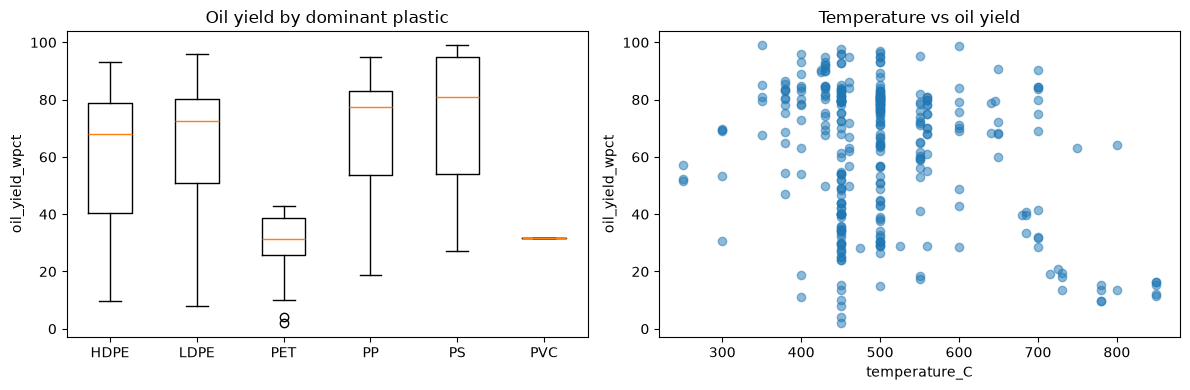

In [3]:
FRACTION_COLS = ["HDPE_wt", "LDPE_wt", "PP_wt", "PS_wt", "PVC_wt", "PET_wt"]
dominant = df[FRACTION_COLS].idxmax(axis=1).str.replace("_wt", "", regex=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = sorted(dominant.unique())
axes[0].boxplot([df.loc[dominant == p, "oil_yield_wpct"] for p in order], tick_labels=order)
axes[0].set_title("Oil yield by dominant plastic"); axes[0].set_ylabel("oil_yield_wpct")
axes[1].scatter(df["temperature_C"], df["oil_yield_wpct"], alpha=0.5)
axes[1].set_xlabel("temperature_C"); axes[1].set_ylabel("oil_yield_wpct")
axes[1].set_title("Temperature vs oil yield")
plt.tight_layout(); plt.show()

## 4. Features and preprocessing

Numeric features (the 6 fractions + 4 conditions) are median-imputed, since
heating rate, particle size, and feed mass are not reported for every row.
Catalyst (Yes/No) and reactor type are one-hot encoded.

In [4]:
COND_NUM = ["temperature_C", "heating_rate_C_min", "particle_size_mm", "feed_mass_g"]
NUM_FEATURES = FRACTION_COLS + COND_NUM
CAT_FEATURES = ["catalyst", "reactor_type"]
FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "oil_yield_wpct"

X = df[FEATURES].copy()
y = df[TARGET].copy()

def make_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])

## 5. Model comparison (cross-validated)

5-fold CV, three models. Compare the MAE against the paper's XGBoost (9.1 %).

In [5]:
def make_models():
    return {
        "RandomForest": RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                                subsample=0.9, colsample_bytree=0.9,
                                random_state=RANDOM_STATE, verbosity=0),
        "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                                  num_leaves=15, min_child_samples=5,
                                  random_state=RANDOM_STATE, verbose=-1),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, oof = [], {}
for name, model in make_models().items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    pred = cross_val_predict(pipe, X, y, cv=cv)
    oof[name] = pred
    rows.append({"model": name, "R2": r2_score(y, pred),
                 "MAE": mean_absolute_error(y, pred),
                 "RMSE": mean_squared_error(y, pred) ** 0.5})
results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print(results.round(3).to_string(index=False))
print("\n(paper benchmark: XGBoost test MAE 9.1 %)")

       model    R2   MAE   RMSE
     XGBoost 0.702 8.962 13.052
    LightGBM 0.704 9.048 13.012
RandomForest 0.682 9.271 13.479

(paper benchmark: XGBoost test MAE 9.1 %)


## 6. Fit the best model and check predicted vs actual

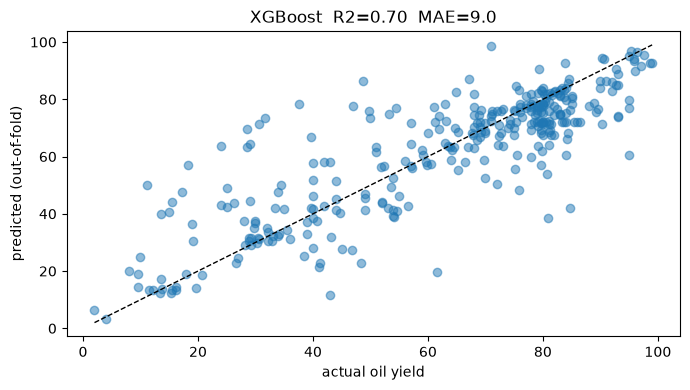

In [6]:
best_name = results.iloc[0]["model"]
final_model = Pipeline([("prep", make_preprocessor()), ("model", make_models()[best_name])])
final_model.fit(X, y)
oof_best = oof[best_name]

plt.scatter(y, oof_best, alpha=0.5)
lims = [min(y.min(), oof_best.min()), max(y.max(), oof_best.max())]
plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("actual oil yield"); plt.ylabel("predicted (out-of-fold)")
plt.title(f"{best_name}  R2={r2_score(y, oof_best):.2f}  MAE={mean_absolute_error(y, oof_best):.1f}")
plt.tight_layout(); plt.show()

## 7. Which conditions matter? (SHAP)

Feature importance for the oil-yield model. Expect temperature and the plastic
fractions (PET/PVC pulling down, polyolefins pushing up) to dominate.

/var/folders/m5/rnwzbv2s35x737bggbrtnksc0000gp/T/ipykernel_22627/1922819334.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_trans, feature_names=feat_names, show=True)


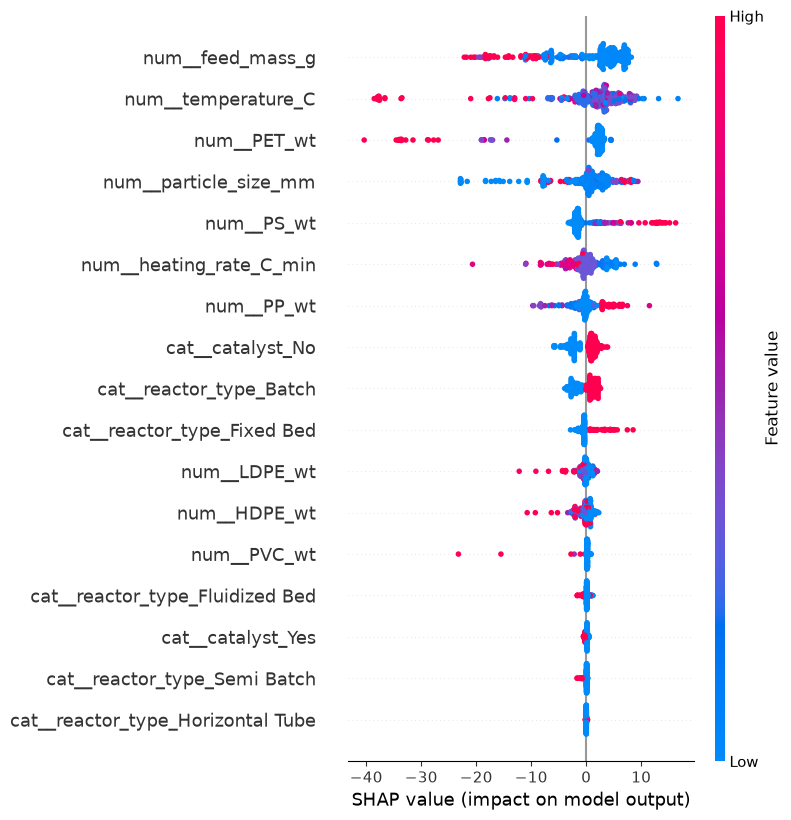

In [7]:
prep = final_model.named_steps["prep"]
model = final_model.named_steps["model"]
X_trans = prep.transform(X)
feat_names = prep.get_feature_names_out()

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_trans)
shap.summary_plot(shap_values, X_trans, feature_names=feat_names, show=True)

## 8. Trust part 1: conformal intervals

Absolute residuals from the out-of-fold predictions give a distribution-free
~90 % interval. We verify the coverage.

In [8]:
ALPHA = 0.10
resid = np.abs(y.values - oof_best)
qhat = float(np.quantile(resid, 1 - ALPHA))
coverage = float(np.mean(resid <= qhat))
print(f"90% conformal half-width: +/- {qhat:.1f} wt%   empirical coverage: {coverage:.2f}")

90% conformal half-width: +/- 21.0 wt%   empirical coverage: 0.90


## 9. Trust part 2: in-domain or extrapolating?

Nearest-neighbour distance in the imputed, standardized, encoded feature space.
A query further from the training data than the 95th percentile of the training
set's own distances is flagged as extrapolating.

In [9]:
ad_prep = Pipeline([("prep", make_preprocessor()), ("scale", StandardScaler())])
X_ad = ad_prep.fit_transform(X)
ad_nn = NearestNeighbors(n_neighbors=6).fit(X_ad)
train_dist = ad_nn.kneighbors(X_ad)[0][:, 1:].mean(axis=1)
AD_THRESHOLD = float(np.quantile(train_dist, 0.95))

def domain_score(conditions: dict):
    row = pd.DataFrame([conditions])[FEATURES]
    d = ad_nn.kneighbors(ad_prep.transform(row))[0][0][:5].mean()
    return float(d), bool(d <= AD_THRESHOLD)

print(f"in-domain threshold: {AD_THRESHOLD:.2f}")

in-domain threshold: 2.74


## 10. Trust-aware oil-yield prediction

In [10]:
def predict_oil(conditions: dict) -> dict:
    """Point oil yield + conformal band + in-domain flag for one condition set."""
    row = pd.DataFrame([conditions])[FEATURES]
    point = float(final_model.predict(row)[0])
    score, in_dom = domain_score(conditions)
    return {"oil_yield_pct": round(point, 1), "band_wpct": round(qhat, 1),
            "in_domain": in_dom, "ad_score": round(score, 2)}


# pure LDPE at a mid temperature (well inside the data) vs a silly extrapolation
ldpe = {c: 0.0 for c in FRACTION_COLS}; ldpe["LDPE_wt"] = 100.0
good = {**ldpe, "temperature_C": 500, "heating_rate_C_min": 10, "particle_size_mm": 2.5,
        "feed_mass_g": 20, "catalyst": "No", "reactor_type": "Fixed Bed"}
silly = {**good, "temperature_C": 1500}

import json
print("in-domain query:       ", json.dumps(predict_oil(good)))
print("out-of-domain (1500 C):", json.dumps(predict_oil(silly)))

in-domain query:        {"oil_yield_pct": 83.5, "band_wpct": 21.0, "in_domain": true, "ad_score": 1.63}
out-of-domain (1500 C): {"oil_yield_pct": 35.7, "band_wpct": 21.0, "in_domain": false, "ad_score": 8.04}


## 11. Condition recommender (maximize oil yield)

Give it a feedstock (the plastic mix) and it random-searches operating conditions
within the studied ranges, keeps only in-domain candidates, and returns the ones
that maximize predicted oil yield.

In [11]:
def recommend_conditions(feedstock: dict, fixed=None, n_candidates=20000, seed=RANDOM_STATE):
    """Best in-domain operating conditions to maximize oil yield for a feedstock mix."""
    rng = np.random.default_rng(seed)
    fixed = fixed or {}
    mix = {c: 0.0 for c in FRACTION_COLS}; mix.update(feedstock)
    cand = {c: np.full(n_candidates, mix[c]) for c in FRACTION_COLS}
    for col in COND_NUM:
        cand[col] = rng.uniform(df[col].min(), df[col].max(), n_candidates)
    for col in CAT_FEATURES:
        cand[col] = rng.choice(sorted(df[col].dropna().unique()), n_candidates)
    for col, val in fixed.items():
        cand[col] = np.full(n_candidates, val)
    C = pd.DataFrame(cand)[FEATURES]

    pred = final_model.predict(C)
    d = ad_nn.kneighbors(ad_prep.transform(C))[0][:, :5].mean(axis=1)
    pred = np.where(d <= AD_THRESHOLD, pred, -np.inf)
    if not np.isfinite(pred).any():
        return {"warning": "no in-domain candidate found"}
    best = int(np.argmax(pred))
    rec = {col: (round(float(cand[col][best]), 1) if col in NUM_FEATURES else str(cand[col][best]))
           for col in FEATURES if col not in FRACTION_COLS}
    return {"feedstock": {c: mix[c] for c in FRACTION_COLS if mix[c] > 0},
            "recommended_conditions": rec, "predicted": predict_oil({**rec, **mix})}


import json
print(json.dumps(recommend_conditions({"PP_wt": 100}), indent=2))
print(json.dumps(recommend_conditions({"LDPE_wt": 50, "PP_wt": 50}), indent=2))

{
  "feedstock": {
    "PP_wt": 100
  },
  "recommended_conditions": {
    "temperature_C": 409.8,
    "heating_rate_C_min": 6.2,
    "particle_size_mm": 20.0,
    "feed_mass_g": 15.7,
    "catalyst": "No",
    "reactor_type": "Batch"
  },
  "predicted": {
    "oil_yield_pct": 85.7,
    "band_wpct": 21.0,
    "in_domain": true,
    "ad_score": 0.94
  }
}
{
  "feedstock": {
    "LDPE_wt": 50,
    "PP_wt": 50
  },
  "recommended_conditions": {
    "temperature_C": 409.8,
    "heating_rate_C_min": 6.2,
    "particle_size_mm": 20.0,
    "feed_mass_g": 15.7,
    "catalyst": "No",
    "reactor_type": "Batch"
  },
  "predicted": {
    "oil_yield_pct": 81.4,
    "band_wpct": 21.0,
    "in_domain": true,
    "ad_score": 1.2
  }
}


## 12. Save

In [12]:
artifact = {
    "model": final_model, "best_name": best_name,
    "features": FEATURES, "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
    "fraction_cols": FRACTION_COLS, "target": TARGET,
    "qhat": qhat, "ad_prep": ad_prep, "ad_nn": ad_nn, "ad_threshold": AD_THRESHOLD,
    "trained_on": "belden2023 (real, oil yield)",
}
out = MODEL_DIR / "pyrolysis_oil_real.joblib"
joblib.dump(artifact, out)
print("saved:", out.resolve())

saved: /Users/Dhanis/plastic-pyrolysis-ml/models/pyrolysis_oil_real.joblib


## 13. Notes and limitations

- **Real but small.** 325 rows from 39 papers, compiled from the literature, so
  it inherits their inconsistencies (missing heating rate / particle size / feed
  mass, imputed here with the median).
- **Oil yield only.** No gas/char split in this dataset. The 3-fraction story
  lives in the synthetic notebook until gas/solid data is compiled by hand.
- **Catalyst is binary** (Yes/No) with no loading or type. That caps how much the
  model can say about catalytic effects.
- **Feedstock sums are not always 100** (`plastic_sum_wt`): some rows are mixed
  waste with non-plastic content. The fractions are used as-is.
- **Benchmark check:** compare the XGBoost MAE above to the paper's 9.1 %. Close
  means the pipeline is sound; the recommender + trust layer are the additions
  on top.